# 04. Results, statistics and figures

Everything here is recomputed from the saved predictions of notebook 03. No number is typed in by hand.

* Main methods are evaluated over 4 subject-disjoint folds x 3 seeds; the few-shot grid has mixed seed coverage and must not be treated as uniformly complete.
* Paired tests: Wilcoxon over the 16 target subjects (seed-averaged per-subject macro-F1) and a paired clip bootstrap per seed.
* t-SNE uses the real features saved for fold 0, seed 0.

**What to send back:** the printed tables (sections 1-3) and the figures.

In [22]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

from picda import config as C
from picda.analysis import (compare, confusion, latex_table, load_results, per_class_f1, per_subject_f1,
                            runs_frame, summary_table)

RUN = C.OUTPUT_DIR / 'benchmark_ctrgcn'   # change to C.OUTPUT_DIR / 'smoke' to test this notebook early
FIG = RUN / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
results = load_results(RUN)
print(len(results), 'result files')

534 result files


## 1. Main table

In [23]:
tab = summary_table(results)
print(tab.to_string())
tab.to_csv(RUN / 'summary.csv')
main = tab.loc[[m for m in tab.index if not m.startswith('fewshot')]]
(RUN / 'table_main.tex').write_text(latex_table(main, 'InHARD-DT to InHARD, 4 subject-disjoint folds x 3 seeds (mean $\\pm$ std).', 'tab:main'))
print('wrote', RUN / 'table_main.tex')

                            runs  acc_mean  acc_std  f1_mean  f1_std  bacc_mean  minutes_per_run
method                                                                                          
dt_in_domain                  12     75.47     3.54    73.32    4.04      73.85             6.93
reverse_zero_shot              3     40.01     0.62    38.76    1.00      40.47             9.53
source_only                   12     50.16     2.97    40.59    2.93      43.58             9.37
dann                          12     46.71     3.89    38.17    3.00      45.76            17.61
coral                         12     48.17     4.00    38.88    3.10      41.41            17.54
mmd                           12     49.21     3.18    39.66    3.00      45.27            17.58
picda                         12     48.35     2.79    39.34    2.50      45.09            17.93
fixmatch                      12     50.75     2.91    40.54    2.93      45.93            12.31
oracle                        

## 2. Paired comparisons

The rows that decide the paper: does any adaptation beat source-only, does the topology term add anything over plain MMD, and does the digital twin add value on top of real labels (source+target vs oracle)?

In [24]:
available = set(runs_frame(results).method)
pairs = [('picda', 'mmd'), ('picda', 'source_only'), ('mmd', 'source_only'), ('coral', 'source_only'),
         ('dann', 'source_only'), ('fixmatch', 'source_only'), ('source_plus_target', 'oracle'),
         ('oracle', 'source_only')]
rows = []
for a, b in pairs:
    if a in available and b in available:
        r = compare(results, a, b)
        w = r['wilcoxon_subjects']
        boots = r['bootstrap_clips']
        rows.append({'a': a, 'b': b, 'mean_subject_diff_pp': 100 * w['mean_diff'], 'wilcoxon_p': w['p'],
                     'boot_diff_pp(seed0)': 100 * boots[0]['diff'] if boots else np.nan,
                     'boot_CI95_pp(seed0)': f"[{100 * boots[0]['ci_low']:.2f}, {100 * boots[0]['ci_high']:.2f}]" if boots else '',
                     'seeds_with_CI_excluding_0': sum((b_['ci_low'] > 0) or (b_['ci_high'] < 0) for b_ in boots)})
cmp_df = pd.DataFrame(rows)
print(cmp_df.round(4).to_string(index=False))
cmp_df.to_csv(RUN / 'comparisons.csv', index=False)

                 a           b  mean_subject_diff_pp  wilcoxon_p  boot_diff_pp(seed0) boot_CI95_pp(seed0)  seeds_with_CI_excluding_0
             picda         mmd               -0.6614      0.4954              -0.5808       [-1.78, 0.67]                          0
             picda source_only               -1.1146      0.1046              -3.2062      [-4.65, -1.74]                          1
               mmd source_only               -0.4533      0.6322              -2.6254      [-3.98, -1.30]                          1
             coral source_only               -1.6064      0.0155              -2.5260      [-3.90, -1.13]                          2
              dann source_only               -2.3145      0.0010              -3.4767      [-4.86, -2.11]                          3
          fixmatch source_only                0.2100      0.8209               0.4603       [-0.92, 1.87]                          1
source_plus_target      oracle                1.7812      0.4332     

## 3. Per-class and per-subject behaviour

                        source_only   mmd  picda  fixmatch  oracle  source_plus_target
Assemble system                60.5  57.3   55.7      58.2    90.8                91.6
Consult sheets                 12.5  14.5   14.7      12.3    30.6                39.0
Picking in front               41.0  40.0   37.7      41.9    80.3                82.3
Picking left                   77.1  78.3   77.5      81.3    87.0                90.6
Put down component             62.5  63.3   65.4      60.2    72.3                76.9
Put down measuring rod         38.9  34.8   32.4      24.9    77.4                72.8
Put down screwdriver           42.0  45.2   47.1      65.1    88.0                88.4
Put down subsystem             39.1  27.5   31.6      24.2    88.5                89.9
Take component                 18.8  20.0   19.8      16.6    74.5                74.0
Take measuring rod             22.2  18.1   17.2      16.9    60.6                61.2
Take screwdriver               62.2  63.9  

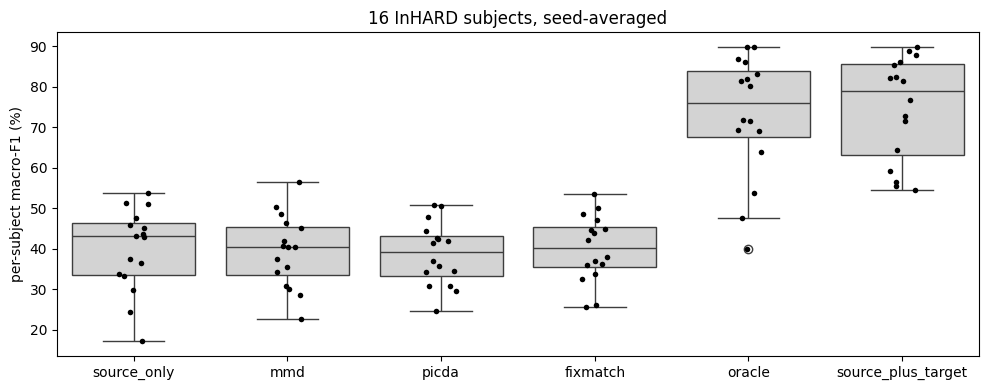

In [25]:
key = [m for m in ['source_only', 'mmd', 'picda', 'fixmatch', 'oracle', 'source_plus_target'] if m in available]
pc = pd.concat([per_class_f1(results, m) for m in key], axis=1).round(1)
print(pc.to_string())
pc.to_csv(RUN / 'per_class_f1.csv')

subj = pd.DataFrame({m: per_subject_f1(results, m).mean(1) for m in key}) * 100
print()
print(subj.round(1).to_string())
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=subj, ax=ax, color='lightgray')
sns.stripplot(data=subj, ax=ax, color='k', size=4)
ax.set_ylabel('per-subject macro-F1 (%)')
ax.set_title('16 InHARD subjects, seed-averaged')
plt.tight_layout()
plt.savefig(FIG / 'per_subject_f1.png', dpi=200)
plt.show()

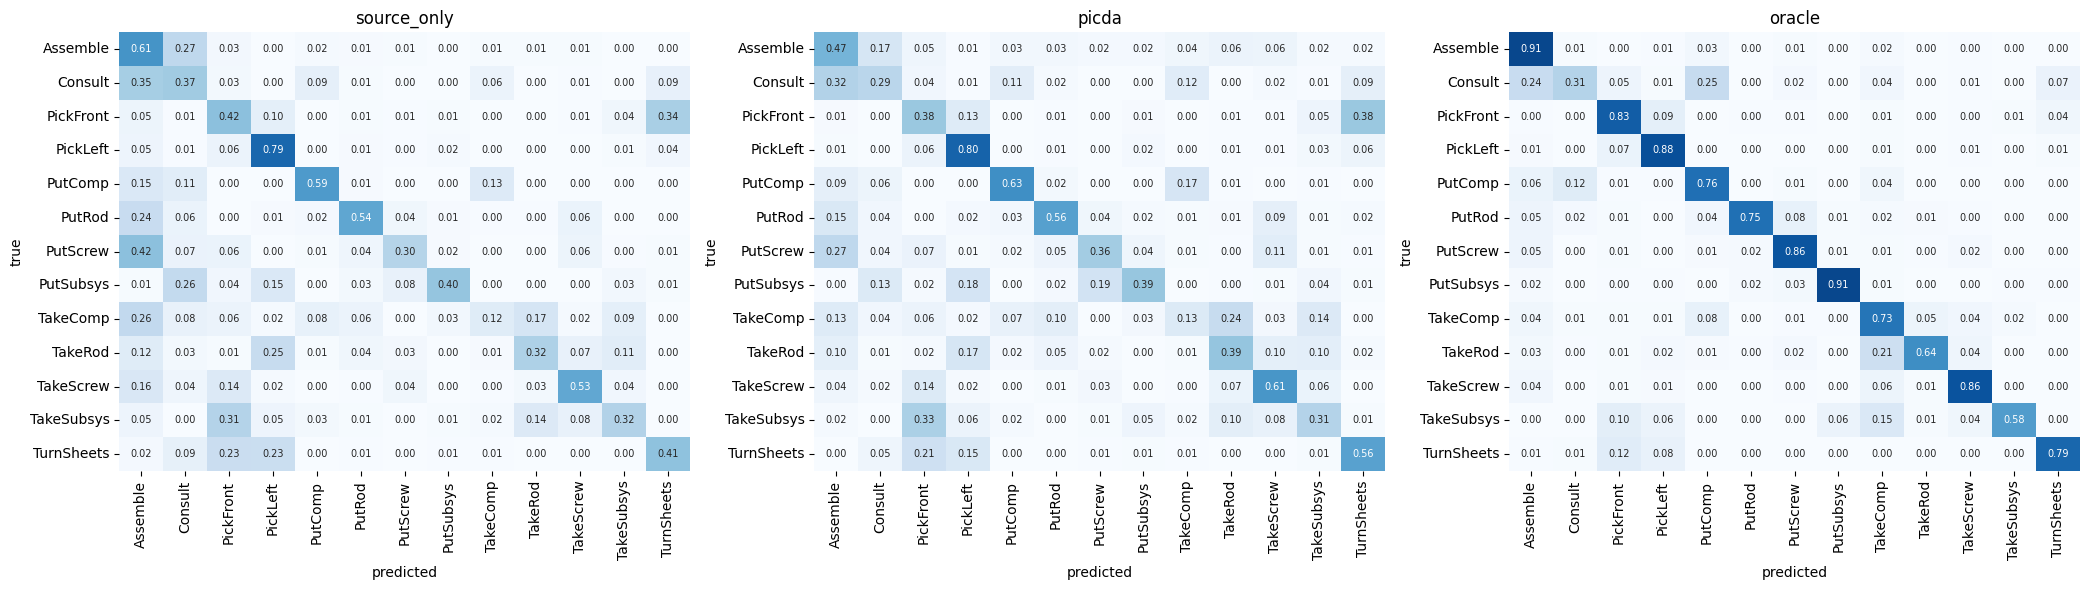

In [26]:
cms = [m for m in ['source_only', 'picda', 'oracle'] if m in available]
fig, axes = plt.subplots(1, len(cms), figsize=(7 * len(cms), 6))
axes = np.atleast_1d(axes)
for ax, m in zip(axes, cms):
    sns.heatmap(confusion(results, m), ax=ax, cmap='Blues', vmin=0, vmax=1, cbar=False,
                xticklabels=C.SHORT_NAMES, yticklabels=C.SHORT_NAMES, annot=True, fmt='.2f', annot_kws={'size': 7})
    ax.set_title(m)
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
plt.tight_layout()
plt.savefig(FIG / 'confusions.png', dpi=200)
plt.show()

## 4. Few-shot curve

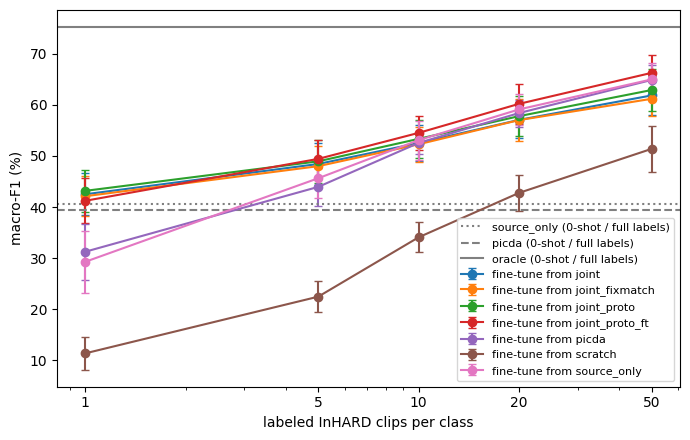

                             k            init  runs  f1_mean  f1_std
method                                                               
fewshot_k1_joint             1           joint    12    42.50    4.09
fewshot_k5_joint             5           joint    12    48.43    4.04
fewshot_k10_joint           10           joint    12    52.54    3.51
fewshot_k20_joint           20           joint    12    57.06    3.60
fewshot_k50_joint           50           joint    12    61.85    3.88
fewshot_k1_joint_fixmatch    1  joint_fixmatch    12    42.12    3.91
fewshot_k5_joint_fixmatch    5  joint_fixmatch    12    48.00    4.04
fewshot_k10_joint_fixmatch  10  joint_fixmatch    12    52.29    3.45
fewshot_k20_joint_fixmatch  20  joint_fixmatch    12    57.02    4.15
fewshot_k50_joint_fixmatch  50  joint_fixmatch    12    61.19    3.42
fewshot_k1_joint_proto       1     joint_proto    12    43.17    4.08
fewshot_k5_joint_proto       5     joint_proto    12    48.95    4.21
fewshot_k10_joint_pr

In [27]:
fs = tab.loc[[m for m in tab.index if m.startswith('fewshot')]].copy()
if len(fs):
    fs['k'] = [int(m.split('_')[1][1:]) for m in fs.index]
    fs['init'] = ['_'.join(m.split('_')[2:]) for m in fs.index]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for init, g in fs.groupby('init'):
        g = g.sort_values('k')
        ax.errorbar(g.k, g.f1_mean, yerr=g.f1_std, marker='o', capsize=3, label=f'fine-tune from {init}')
    for m, ls in [('source_only', ':'), ('picda', '--'), ('oracle', '-')]:
        if m in tab.index:
            ax.axhline(tab.loc[m, 'f1_mean'], ls=ls, color='gray', label=f'{m} (0-shot / full labels)')
    ax.set_xscale('log')
    ax.set_xticks(sorted(fs.k.unique()))
    ax.set_xticklabels(sorted(fs.k.unique()))
    ax.set_xlabel('labeled InHARD clips per class')
    ax.set_ylabel('macro-F1 (%)')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(FIG / 'few_shot.png', dpi=200)
    plt.show()
    print(fs[['k', 'init', 'runs', 'f1_mean', 'f1_std']].sort_values(['init', 'k']).to_string())

## 5. Feature space (real features, fold 0, seed 0)

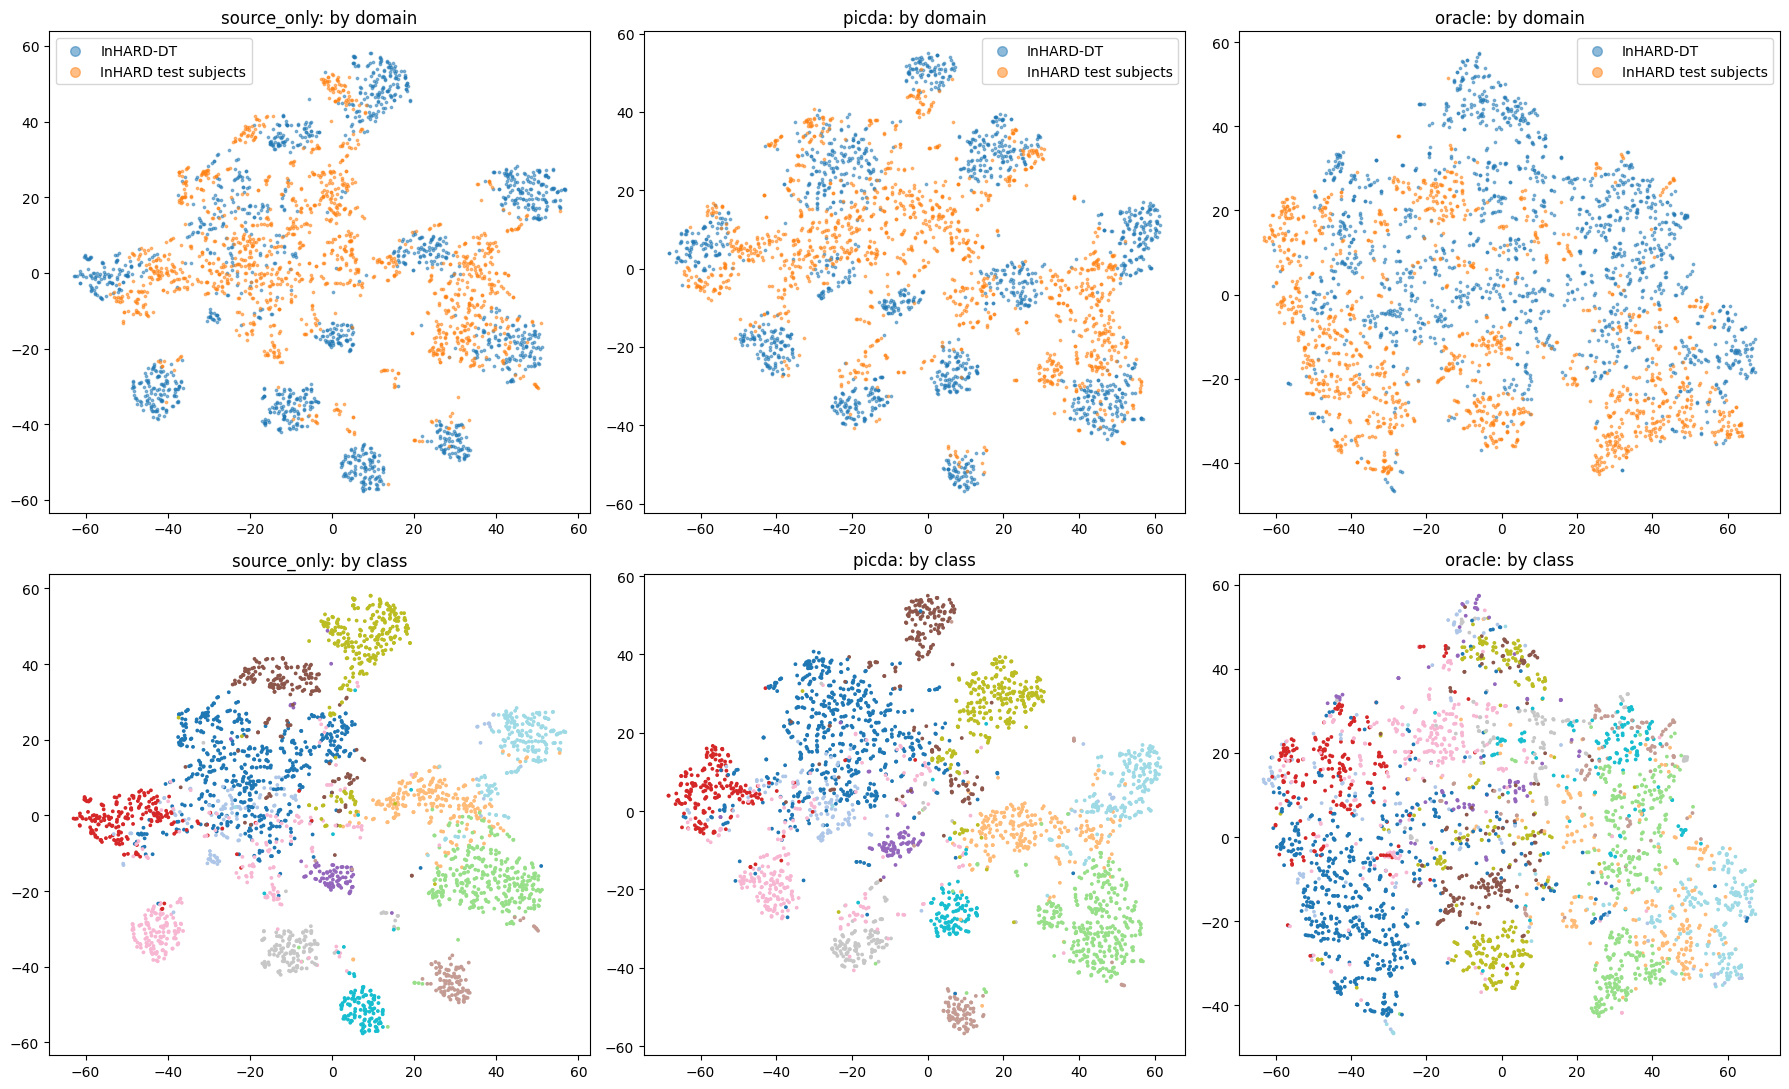

In [28]:
feat_files = {m: RUN / 'features' / f'{m}_fold0_seed0.npz' for m in ['source_only', 'picda', 'oracle']}
feat_files = {m: p for m, p in feat_files.items() if p.exists()}
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, len(feat_files), figsize=(6 * len(feat_files), 11), squeeze=False)
for col, (m, p) in enumerate(feat_files.items()):
    z = np.load(p)
    si = rng.choice(len(z['feats_src']), size=min(1500, len(z['feats_src'])), replace=False)
    X = np.concatenate([z['feats_src'][si], z['feats_tgt']])
    dom = np.r_[np.zeros(len(si)), np.ones(len(z['feats_tgt']))]
    y = np.r_[z['y_src'][si], z['y_tgt']]
    E = TSNE(n_components=2, perplexity=30, init='pca', random_state=0).fit_transform(X)
    axes[0, col].scatter(E[dom == 0, 0], E[dom == 0, 1], s=3, alpha=0.5, label='InHARD-DT')
    axes[0, col].scatter(E[dom == 1, 0], E[dom == 1, 1], s=3, alpha=0.5, label='InHARD test subjects')
    axes[0, col].set_title(f'{m}: by domain')
    axes[0, col].legend(markerscale=4)
    sc = axes[1, col].scatter(E[:, 0], E[:, 1], c=y, cmap='tab20', s=3)
    axes[1, col].set_title(f'{m}: by class')
plt.tight_layout()
plt.savefig(FIG / 'tsne.png', dpi=200)
plt.show()